# 운영 기준 전환 A/B Test 분석

## 분석 목적
- 기존 ARPU 기반 운영 기준과 신규 NAU 기반 운영 기준 성과 비교
- 핵심 지표 CVR(Download / Click) 개선 여부 검증
- Proportion Z-Test 및 Fisher Exact Test 기반 통계적 유의성 확인
- Download 성과 동반 확인

## 실험 구조
- Korea: 2025-07-17 ~ 2025-09-10, 8주
- Brazil: 2025-07-31 ~ 2025-08-27, 4주
- 전반부: Device Group A = NAU, Device Group B = ARPU
- 후반부: Device Group A = ARPU, Device Group B = NAU
- 단말군별 기본 특성 영향 완화를 위한 Cross-over 설계

## 데이터 안내
- 실제 프로젝트 Python 코드 구조 기반 공개용 재구성
- 실제 회사 데이터 및 내부 식별 정보 미포함
- `sample_ab_test.csv`의 일별 값은 공개용 합성 데이터
- README에 공개한 국가별 최종 집계값과 동일한 합계 구조
- 사내 원본의 주차별 raw data, component metadata, 국가 변환 파일 merge 구간만 샘플 CSV 로드로 대체

## 1. 라이브러리 및 샘플 데이터 로드

- 원본 코드의 주요 라이브러리 구성 유지
- 내부 파일 경로 및 업무용 Excel merge 로직 제거
- 공개용 `sample_ab_test.csv` 입력으로 대체
- 원본 분석 코드와 동일한 컬럼명으로 변환

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import fisher_exact

# GitHub / 로컬 실행 환경 대응
candidate_paths = [
    Path('../sample_data/sample_ab_test.csv'),
    Path('01_ab_test/sample_data/sample_ab_test.csv'),
    Path('sample_data/sample_ab_test.csv'),
    Path('sample_ab_test.csv')
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError('sample_ab_test.csv 파일 경로 확인 필요')

# 공개용 샘플 데이터 로드
c_raw = pd.read_csv(DATA_PATH)

# 원본 분석 코드의 컬럼명 유지
c_raw = c_raw.rename(columns={
    'week': 'Week',
    'country': 'Country',
    'device_group': 'Target',
    'impression': 'Impression',
    'click': 'Click',
    'download': 'Download'
})

# 원본과 동일한 date 정리
c_raw['date'] = pd.to_datetime(c_raw['date']).dt.normalize()

df = c_raw.copy()

df.head()

,date,Week,Country,Target,Impression,Click,Download
0,2025-07-17,W29,Korea,A,1639,37,4
1,2025-07-17,W29,Korea,B,1761,38,3
2,2025-07-18,W29,Korea,A,1792,43,5
3,2025-07-18,W29,Korea,B,1869,41,3
4,2025-07-19,W29,Korea,A,1834,44,6


## 2. 분석 기간 및 대상 국가 필터링

- Korea : W29~W36
- Brazil : W31~W34
- 원본 코드의 국가별 실험 기간 필터 유지

In [ ]:
# Korea: W29 ~ W36
# Brazil: W31 ~ W34
df_filtered = df[
    ~df['Week'].isin(['W29', 'W30']) | (df['Country'] == 'Korea')
]

df_filtered = df_filtered[
    ~df_filtered['Week'].isin(['W35', 'W36']) | (df_filtered['Country'] == 'Korea')
]

df = df_filtered.copy()

df.groupby('Country')['Week'].unique()

Country
Brazil                        [W31, W32, W33, W34]
Korea     [W29, W30, W31, W32, W33, W34, W35, W36]
Name: Week, dtype: object

## 3. Cross-over 기준 재매핑

- 전반부 W29~W32: A → NAU, B → ARPU
- 후반부 W33~W36: A → ARPU, B → NAU
- 단말군별 사용자 규모 및 기본 행동 성향 차이 영향 완화

In [ ]:
# 전반부
df1 = df[
    (df['Target'].isin(['A', 'B'])) &
    (df['Week'].isin(['W29', 'W30', 'W31', 'W32']))
].copy()

df1['Target'] = df1['Target'].replace({
    'A': 'NAU',
    'B': 'ARPU'
})

# 후반부
df2 = df[
    (df['Target'].isin(['A', 'B'])) &
    (df['Week'].isin(['W33', 'W34', 'W35', 'W36']))
].copy()

df2['Target'] = df2['Target'].replace({
    'A': 'ARPU',
    'B': 'NAU'
})

df = pd.concat([df1, df2], axis=0).sort_values(
    ['Country', 'date', 'Target']
).reset_index(drop=True)

df.head()

,date,Week,Country,Target,Impression,Click,Download
0,2025-07-31,W31,Brazil,ARPU,18683,211,35
1,2025-07-31,W31,Brazil,NAU,18642,258,71
2,2025-08-01,W31,Brazil,ARPU,20861,231,40
3,2025-08-01,W31,Brazil,NAU,21338,323,99
4,2025-08-02,W31,Brazil,ARPU,20042,233,41


## 4. 기초 통계량

- Week × Country × Target 단위 합계 및 평균
- Country × Target 단위 최종 성과 집계
- Impression, Click, Download 기준 비교

In [ ]:
weekly_stats = (
    df.groupby(['Week', 'Country', 'Target'])
      [['Impression', 'Click', 'Download']]
      .agg(['sum', 'mean'])
      .reset_index()
)

country_stats = (
    df.groupby(['Country', 'Target'])
      [['Impression', 'Click', 'Download']]
      .agg(['sum', 'mean'])
      .reset_index()
)

country_stats

Country Target Impression               Click             Download           
                        sum          mean   sum        mean      sum       mean
0  Brazil   ARPU     507287  18117.392857  5302  189.357143      825  29.464286
1  Brazil    NAU     518231  18508.250000  7253  259.035714     1956  69.857143
2   Korea   ARPU      92250   1647.321429  1821   32.517857      135   2.410714
3   Korea    NAU      92108   1644.785714  2003   35.767857      229   4.089286

## 5. Korea 일별 Click / Download 추이
- 공개용 데이터 기반 일별 패턴

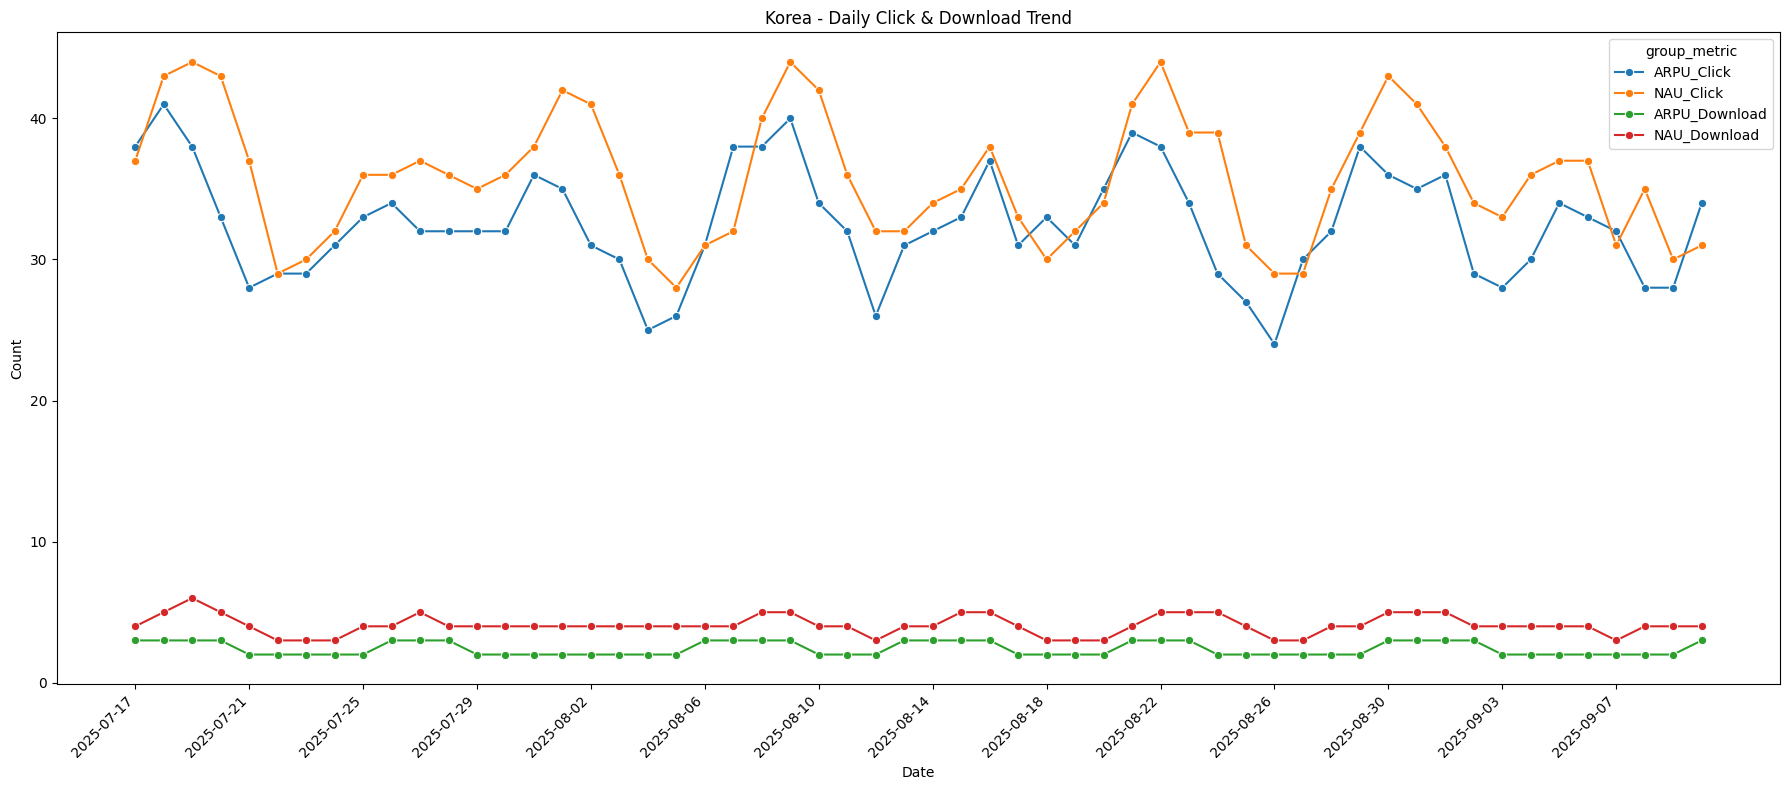

In [ ]:
df_kor = df[df['Country'] == 'Korea']

df_kor = df_kor.melt(
    id_vars=['Week', 'date', 'Target'],
    value_vars=['Click', 'Download'],
    var_name='metric',
    value_name='value'
)

df_kor['group_metric'] = (
    df_kor['Target'] + '_' + df_kor['metric']
)

plt.figure(figsize=(18, 8))

sns.lineplot(
    data=df_kor,
    x='date',
    y='value',
    hue='group_metric',
    marker='o',
    errorbar=None
)

plt.title('Korea - Daily Click & Download Trend')
plt.ylabel('Count')
plt.xlabel('Date')

dates = df_kor['date'].sort_values().unique()
plt.xticks(
    dates[::4],
    [pd.Timestamp(d).strftime('%Y-%m-%d') for d in dates[::4]],
    rotation=45,
    ha='right'
)

plt.tight_layout()
plt.show()

## 6. Brazil 일별 Click / Download 추이
- 공개용 데이터 기반 일별 패턴

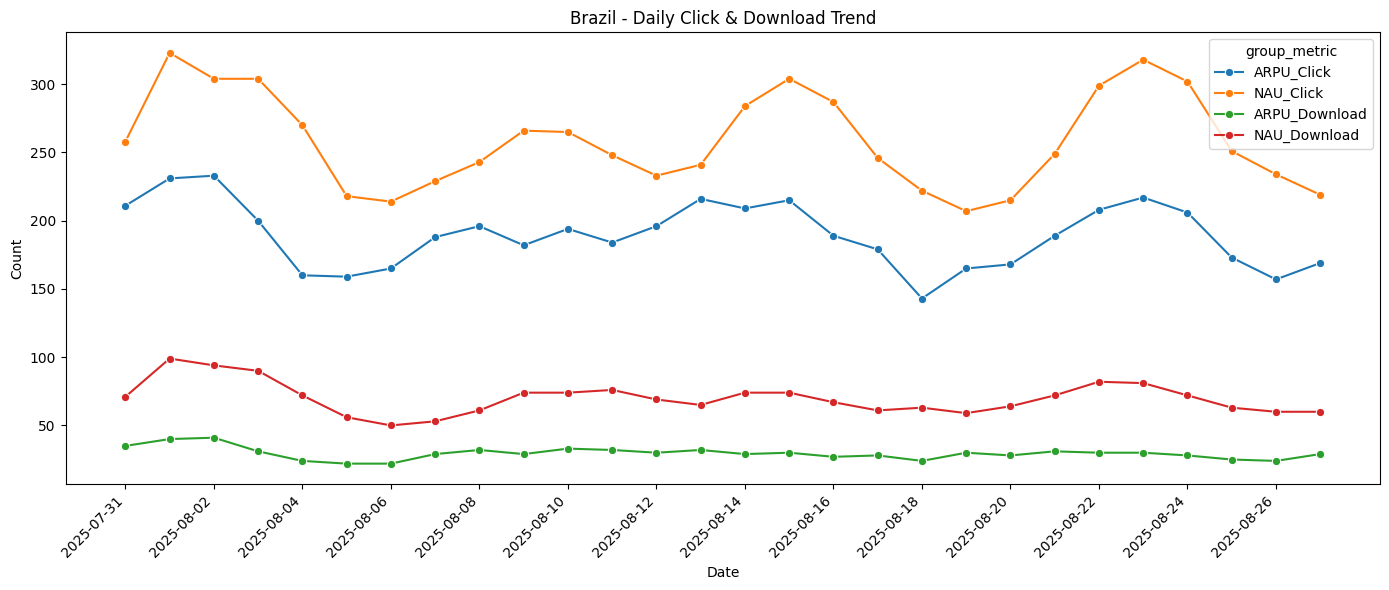

In [ ]:
df_bra = df[df['Country'] == 'Brazil']

df_bra = df_bra.melt(
    id_vars=['Week', 'date', 'Target'],
    value_vars=['Click', 'Download'],
    var_name='metric',
    value_name='value'
)

df_bra['group_metric'] = (
    df_bra['Target'] + '_' + df_bra['metric']
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df_bra,
    x='date',
    y='value',
    hue='group_metric',
    marker='o',
    errorbar=None
)

plt.title('Brazil - Daily Click & Download Trend')
plt.ylabel('Count')
plt.xlabel('Date')

dates = df_bra['date'].sort_values().unique()
plt.xticks(
    dates[::2],
    [pd.Timestamp(d).strftime('%Y-%m-%d') for d in dates[::2]],
    rotation=45,
    ha='right'
)

plt.tight_layout()
plt.show()

## 7. Z-Test 정규근사 조건 확인

- CVR = Download / Click 형태의 비율 지표
- 성공 수 = Download
- 실패 수 = Click - Download
- 각 집단의 성공·실패 수 5 이상 여부 확인
- 원본 초안의 `A/B` 참조를 Cross-over 재매핑 이후 `NAU/ARPU` 기준으로 수정

In [ ]:
def ok_for_z(success, trials, thresh=5):
    fail = trials - success
    return (success >= thresh) and (fail >= thresh)


report = []

for country, sub in df.groupby('Country'):
    g = (
        sub.groupby('Target')
           .agg(
               Click=('Click', 'sum'),
               Download=('Download', 'sum')
           )
    )

    if not {'NAU', 'ARPU'}.issubset(g.index):
        report.append({
            'Country': country,
            'Z-Test_Ready': False,
            'Reason': 'NAU/ARPU 한쪽 부재'
        })
        continue

    clk_nau = int(g.loc['NAU', 'Click'])
    dl_nau = int(g.loc['NAU', 'Download'])

    clk_arpu = int(g.loc['ARPU', 'Click'])
    dl_arpu = int(g.loc['ARPU', 'Download'])

    rule_ok_nau = ok_for_z(dl_nau, clk_nau, 5)
    rule_ok_arpu = ok_for_z(dl_arpu, clk_arpu, 5)

    report.append({
        'Country': country,
        'NAU_Success': dl_nau,
        'NAU_Fail': clk_nau - dl_nau,
        'ARPU_Success': dl_arpu,
        'ARPU_Fail': clk_arpu - dl_arpu,
        'Z-Test_Ready': rule_ok_nau and rule_ok_arpu
    })

z_test_check = pd.DataFrame(report)
z_test_check

,Country,NAU_Success,NAU_Fail,ARPU_Success,ARPU_Fail,Z-Test_Ready
0,Brazil,1956,5297,825,4477,True
1,Korea,229,1774,135,1686,True


## 8. 국가별 기본 지표 및 Proportion Z-Test
- Impression, Click, Download 집계
- CTR = Click / Impression
- CVR = Download / Click
- NAU > ARPU 방향의 단측 Proportion Z-Test
- 핵심 판단 지표 CVR

,Target,Impression,Click,Download,CTR,CVR,IPM
0,ARPU,92250,1821,135,0.019740,0.074135,1.463415
1,NAU,92108,2003,229,0.021746,0.114329,2.486212


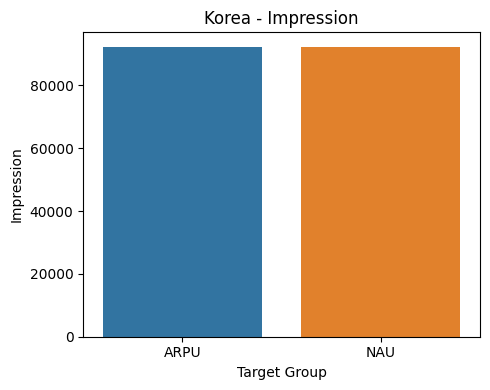

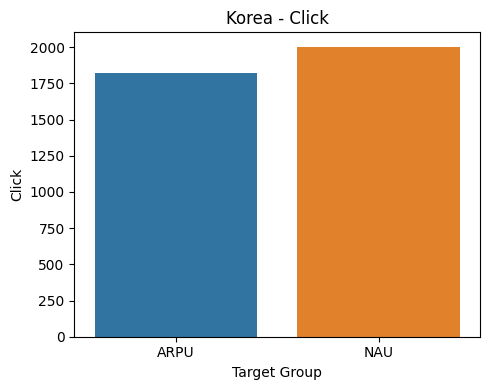

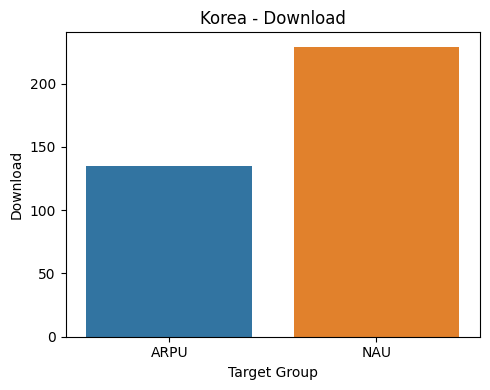

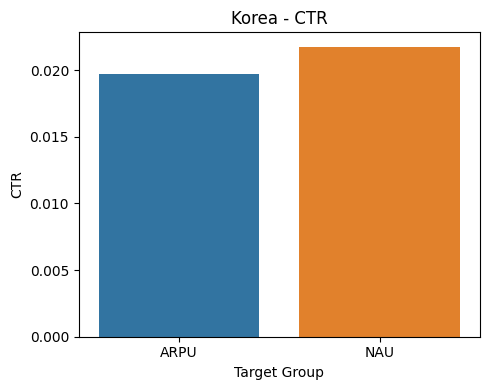

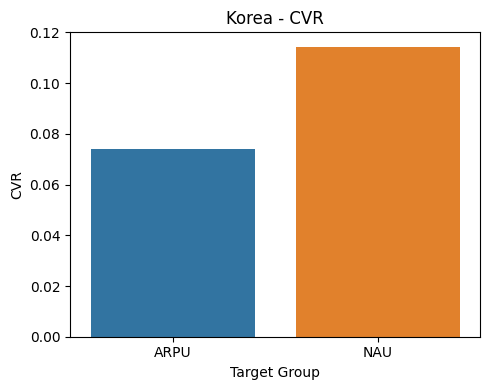


[Korea]
CTR p-value : 0.001254 → 유의
CVR p-value : 0.000012 → 유의


,Target,Impression,Click,Download,CTR,CVR,IPM
0,ARPU,507287,5302,825,0.010452,0.155602,1.626298
1,NAU,518231,7253,1956,0.013996,0.269682,3.774379


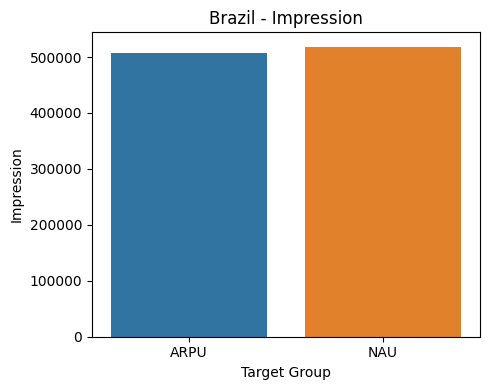

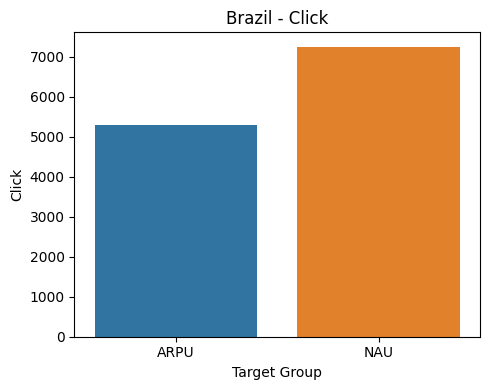

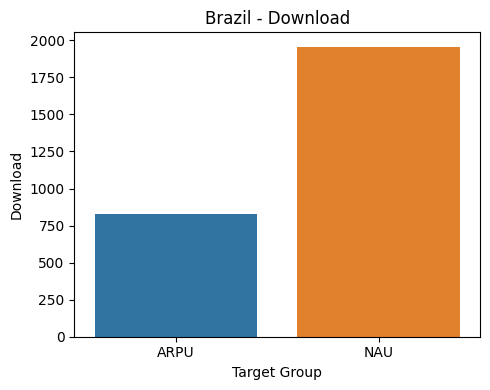

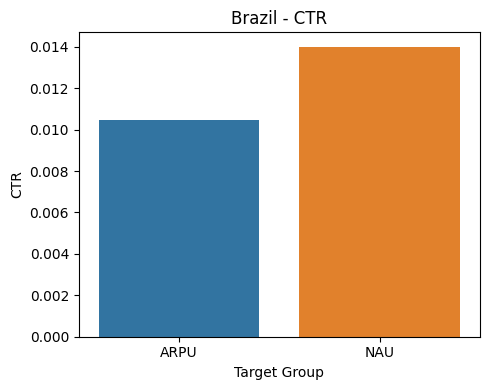

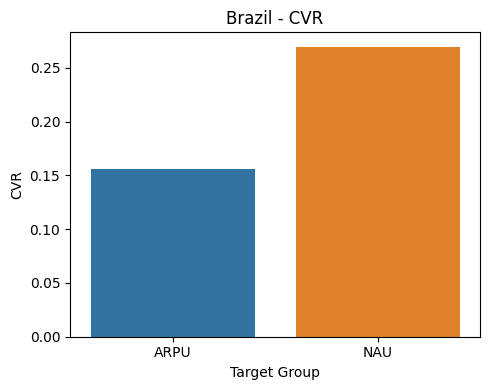


[Brazil]
CTR p-value : 0.000000 → 유의
CVR p-value : 0.000000 → 유의


In [ ]:
def analyze_country(df, country_name):
    sub = df[df['Country'] == country_name]

    if sub.empty:
        print(f'[{country_name}] 데이터 없음')
        return

    ## 집계
    summary = (
        sub.groupby('Target', as_index=False)
           .agg({
               'Impression': 'sum',
               'Click': 'sum',
               'Download': 'sum'
           })
    )

    summary['CTR'] = (
        summary['Click'] / summary['Impression']
    )

    summary['CVR'] = (
        summary['Download'] / summary['Click']
    )

    summary['IPM'] = (
        summary['Download'] / summary['Impression'] * 1000
    )

    display(summary)

    # 기본 지표 시각화
    for col in ['Impression', 'Click', 'Download']:
        plt.figure(figsize=(5, 4))

        sns.barplot(
            data=summary,
            x='Target',
            y=col,
            hue='Target',
            legend=False
        )

        plt.title(f'{country_name} - {col}')
        plt.ylabel(col)
        plt.xlabel('Target Group')
        plt.tight_layout()
        plt.show()

    for col in ['CTR', 'CVR']:
        plt.figure(figsize=(5, 4))

        sns.barplot(
            data=summary,
            x='Target',
            y=col,
            hue='Target',
            legend=False
        )

        plt.title(f'{country_name} - {col}')
        plt.ylabel(col)
        plt.xlabel('Target Group')
        plt.tight_layout()
        plt.show()

    ## CTR 검정
    ctr_counts = [
        summary.loc[
            summary['Target'] == 'NAU',
            'Click'
        ].values[0],

        summary.loc[
            summary['Target'] == 'ARPU',
            'Click'
        ].values[0]
    ]

    ctr_nobs = [
        summary.loc[
            summary['Target'] == 'NAU',
            'Impression'
        ].values[0],

        summary.loc[
            summary['Target'] == 'ARPU',
            'Impression'
        ].values[0]
    ]

    _, p_ctr = proportions_ztest(
        count=ctr_counts,
        nobs=ctr_nobs,
        alternative='larger'
    )

    ## CVR 검정
    cvr_counts = [
        summary.loc[
            summary['Target'] == 'NAU',
            'Download'
        ].values[0],

        summary.loc[
            summary['Target'] == 'ARPU',
            'Download'
        ].values[0]
    ]

    cvr_nobs = [
        summary.loc[
            summary['Target'] == 'NAU',
            'Click'
        ].values[0],

        summary.loc[
            summary['Target'] == 'ARPU',
            'Click'
        ].values[0]
    ]

    _, p_cvr = proportions_ztest(
        count=cvr_counts,
        nobs=cvr_nobs,
        alternative='larger'
    )

    print(f'\n[{country_name}]')
    print(
        f"CTR p-value : {p_ctr:.6f} "
        f"→ {'유의' if p_ctr < 0.05 else '유의하지 않음'}"
    )
    print(
        f"CVR p-value : {p_cvr:.6f} "
        f"→ {'유의' if p_cvr < 0.05 else '유의하지 않음'}"
    )

    return summary


kor_summary = analyze_country(df, 'Korea')
bra_summary = analyze_country(df, 'Brazil')

## 9. CVR Proportion Z-Test / Fisher Exact Test 교차 검증
- CVR 기준 2×2 contingency table 구성
- Proportion Z-Test와 Fisher Exact Test 교차 확인
- 단측 대립가설: CVR_NAU > CVR_ARPU

In [ ]:
def fisher(df, country_name):
    sub = df[df['Country'] == country_name]

    if sub.empty:
        print(f'[{country_name}] 데이터 없음')
        return

    ## 집계
    g = (
        sub.groupby('Target')
           .agg(
               Impression=('Impression', 'sum'),
               Click=('Click', 'sum'),
               Download=('Download', 'sum')
           )
    )

    if not {'NAU', 'ARPU'}.issubset(g.index):
        print(f'{country_name} NAU/ARPU 데이터 확인 필요')
        return

    impA = int(g.loc['NAU', 'Impression'])
    clkA = int(g.loc['NAU', 'Click'])
    dlA = int(g.loc['NAU', 'Download'])

    impB = int(g.loc['ARPU', 'Impression'])
    clkB = int(g.loc['ARPU', 'Click'])
    dlB = int(g.loc['ARPU', 'Download'])

    print(f'\n==== {country_name} A/B Test ====')
    print(
        f'NAU  : CVR = '
        f'{dlA / clkA if clkA > 0 else np.nan:.4f}'
    )
    print(
        f'ARPU : CVR = '
        f'{dlB / clkB if clkB > 0 else np.nan:.4f}'
    )

    results = {}

    ## CVR 검정
    if min(clkA, clkB) > 0:
        cvr_counts = [dlA, dlB]
        cvr_nobs = [clkA, clkB]

        z_cvr, p_cvr = proportions_ztest(
            count=cvr_counts,
            nobs=cvr_nobs,
            alternative='larger'
        )

        # Fisher Exact Test
        cvr_table = [
            [dlA, clkA - dlA],
            [dlB, clkB - dlB]
        ]

        odds_ratio, p_cvr_f = fisher_exact(
            cvr_table,
            alternative='greater'
        )

        results['CVR'] = {
            'z_stat': z_cvr,
            'z-test_p': p_cvr,
            'odds_ratio': odds_ratio,
            'fisher_p': p_cvr_f
        }

    else:
        results['CVR'] = {
            'note': 'click=0 포함'
        }

    print(
        '검정결과:',
        {
            'CVR': {
                key: (
                    f'{value:.6f}'
                    if isinstance(value, (float, np.floating))
                    else value
                )
                for key, value in results['CVR'].items()
            }
        }
    )

    return results


kor_test = fisher(df, 'Korea')
bra_test = fisher(df, 'Brazil')


==== Korea A/B Test ====
NAU  : CVR = 0.1143
ARPU : CVR = 0.0741
검정결과: {'CVR': {'z_stat': '4.229807', 'z-test_p': '0.000012', 'odds_ratio': '1.612151', 'fisher_p': '0.000013'}}

==== Brazil A/B Test ====
NAU  : CVR = 0.2697
ARPU : CVR = 0.1556
검정결과: {'CVR': {'z_stat': '15.204052', 'z-test_p': '0.000000', 'odds_ratio': '2.003881', 'fisher_p': '0.000000'}}


## 10. 최종 결과 요약

- Korea CVR: ARPU 7.41% → NAU 11.43%
- Korea CVR 상대 개선: 약 +54%
- Korea Download: 135 → 229, 약 +70%
- Brazil CVR: ARPU 15.56% → NAU 26.97%
- Brazil CVR 상대 개선: 약 +73%
- Brazil Download: 825 → 1,956, 약 +137%
- 양 국가 Proportion Z-Test 및 Fisher Exact Test `p < 0.05`
- NAU 기반 운영 기준 전환 근거 확보

## 공개용 코드 수정 범위
- 사내 raw CSV / component metadata / 국가 변환 파일 merge 구간 제거
- 공개용 sample CSV 로드로 대체
- 내부 파일명, 컬럼명, 식별자 제거
- 실제 프로젝트의 Cross-over 재매핑, 국가별 집계, 지표 계산, Z-Test, Fisher 검정 구조 유지